Исследование факторов кредитного риска и построение скоринговой модели

Бизнес-цель проекта: Выявить статистически значимые финансовые, поведенческие и социально-демографические паттерны, отличающие надежных заемщиков от проблемных. На основе комплексного профиля клиента, объединяющего сложные аналитические метрики (дисперсия баланса, долговая нагрузка) с базовыми историческими атрибутами (возраст, параметры кредита, активность по счету), построить многофакторную предиктивную ML-модель кредитного скоринга.

Ценность для бизнеса:

Кредитование - это управление рисками. Каждый выданный кредит, по которому наступает дефолт, приносит банку прямые убытки и требует заморозки капитала в резервах. Понимание статистически значимых предикторов дефолта позволит:

    1.Снизить финансовые потери за счет раннего отсева высокорисковых клиентов.

    2.Оптимизировать кредитную политику, сделав процесс одобрения  более прозрачным и управляемым, опираясь на математические доказательства, а не на интуицию экспертов.

Проект построен по классическому пайплайну коммерческой аналитики и состоит из трех последовательных этапов:

Сбор и агрегация данных (SQL): Формирование аналитической витрины из сырых логов транзакций.

Разведочный анализ и статистика (Python, EDA): Визуальная и математическая проверка бизнес-гипотез о факторах риска (влияние дисперсии баланса и долговой нагрузки) с использованием непараметрических статистических критериев.

Машинное обучение (ML): Построение логистической регрессии для оценки индивидуальной вероятности дефолта новых клиентов на с использованием метрик, успешно прошедших статистическую проверку.

In [25]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

Этап 1. Сбор и агрегация данных (SQL): Формирование аналитической витрины из сырых логов транзакци

In [26]:
con = duckdb.connect('C:/Users/HONOR/Desktop/pet_project_credit_score/data/processed/banking_project.db')

Для начала соберем единую аналитическую витрину с помощью SQL, отфильтровав только реальных владельцев счетов, рассчитав их поведенческие метрики (частоту транзакций, средний баланс, объемы пополнений и списаний) и присоединив все это к таблице выданных кредитов. С помощью оконных функций, мы добавили в профиль клиента метрики динамики: максимальным периодом без операций, максимальным падением баланса и минимальным скользящим остатком. Также была рассчитана ключевая банковская метрика DTI (Debt-to-Income) с учетом фактического возраста счета в месяцах, а все даты приведены к корректному календарному формату. Это позволило нам превратить сырые данные в единую плоскую таблицу. Каждая строка представляет собой отдельный кредитный кейс с готовым количественным профилем заемщика, что необходимо для дальнейшего разведочного анализа и проверки статистических гипотез.

Архитектурный нюанс: В реальном банковском скоринге модель должна принимать решение строго на момент подачи заявки, то есть до даты loan_date. Если транзакции, совершенные после выдачи кредита, попадают в агрегацию, возникает так называемая утечка данных: целевое событие (дефолт) начинает напрямую влиять на признаки (счет блокируется, баланс обнуляется, транзакции замирают). Алгоритм выучивает эти «последствия», из-за чего показывает фантастически высокий, но нереалистичный ROC-AUC в районе 0.95.

Чтобы сделать модель честной и применимой в продакшене, в SQL-запросе мы применяем жесткую фильтрацию: агрегируем данные строго с условием date < loan.loan_date

In [27]:
sql_query_1 = """WITH account_owners AS
(SELECT account_id, client_id
FROM read_csv_auto('C:/Users/HONOR/Desktop/pet_project_credit_score/data/raw/disp.csv')
WHERE type = 'OWNER'), 

loan AS 
(SELECT loan_id, account_id, amount, duration, payments, status, strptime(CAST(date AS VARCHAR), '%y%m%d') AS loan_date
FROM read_csv_auto('C:/Users/HONOR/Desktop/pet_project_credit_score/data/raw/loan.csv')),

transactions AS
(SELECT * FROM read_csv_auto('C:/Users/HONOR/Desktop/pet_project_credit_score/data/raw/trans.csv')),

trans_windows AS
(SELECT trans_id, account_id, strptime(CAST(date AS VARCHAR), '%y%m%d') as date, type, transactions.amount, balance, 
LAG(balance) OVER(PARTITION BY account_id ORDER BY strptime(CAST(date AS VARCHAR), '%y%m%d'), trans_id) AS prev_balance, 
LAG(strptime(CAST(date AS VARCHAR), '%y%m%d')) OVER(PARTITION BY account_id ORDER BY strptime(CAST(date AS VARCHAR), '%y%m%d'), trans_id) AS prev_date, 
AVG(balance) OVER(PARTITION BY account_id ORDER BY strptime(CAST(date AS VARCHAR), '%y%m%d'), trans_id ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS rolling_avg_3_trans
FROM transactions
INNER JOIN loan USING(account_id)
WHERE strptime(CAST(date AS VARCHAR), '%y%m%d') < loan.loan_date), 

transaction_metrics AS
(SELECT account_id, COUNT(trans_id) as trans_per_user, ROUND(AVG(balance), 2) AS avg_balance,
SUM(amount) FILTER (WHERE type = 'PRIJEM') as replenishment_per_user,
SUM(amount) FILTER (WHERE type = 'VYDAJ') as debt_per_user,
MAX(date - prev_date) AS max_days_without_ops, MAX(prev_balance - balance) AS max_balance_drop, MIN(rolling_avg_3_trans) AS min_rolling_balance,
MIN(date) AS first_trans_date,
VAR_SAMP(balance) AS balance_variance
FROM trans_windows
GROUP BY account_id), 

clients AS
(SELECT client_id, 
CAST(SUBSTRING(CAST(birth_number AS VARCHAR), 1, 2) AS INT) + 1900 AS birth_year
FROM read_csv_auto('C:/Users/HONOR/Desktop/pet_project_credit_score/data/raw/client.csv'))

SELECT loan.loan_id, account_id, loan.amount, loan.duration, loan.payments,
loan.status, account_owners.client_id, 
EXTRACT(YEAR FROM loan.loan_date) - clients.birth_year AS client_age,
transaction_metrics.trans_per_user, loan.loan_date,
transaction_metrics.avg_balance, 
transaction_metrics.replenishment_per_user, transaction_metrics.debt_per_user,
transaction_metrics.max_balance_drop, transaction_metrics.max_days_without_ops, transaction_metrics.min_rolling_balance,
transaction_metrics.balance_variance,
loan.payments / (transaction_metrics.replenishment_per_user / GREATEST(date_diff('month', transaction_metrics.first_trans_date, loan.loan_date), 1)) AS DTI
FROM loan
LEFT JOIN account_owners USING(account_id)
LEFT JOIN transaction_metrics USING(account_id)
LEFT JOIN clients USING(client_id)
ORDER BY loan_id"""




In [28]:
con.execute(f"CREATE OR REPLACE TABLE datamart_loans AS {sql_query_1}")
main_df = con.execute("SELECT * FROM datamart_loans").df()
print(main_df)

     loan_id  account_id  amount  duration  payments status  client_id  \
0       4959           2   80952        24    3373.0      A          2   
1       4961          19   30276        12    2523.0      B         25   
2       4962          25   30276        12    2523.0      A         31   
3       4967          37  318480        60    5308.0      D         45   
4       4968          38  110736        48    2307.0      C         46   
..       ...         ...     ...       ...       ...    ...        ...   
677     7294       11327   39168        24    1632.0      C      13923   
678     7295       11328  280440        60    4674.0      C      13924   
679     7304       11349  419880        60    6998.0      C      13955   
680     7305       11359   54024        12    4502.0      A      13968   
681     7308       11362  129408        24    5392.0      A      13971   

     client_age  trans_per_user  loan_date  avg_balance  \
0            49              54 1994-01-05     32590

Еще раз пройдемся по содержательным значениям полей результирующей таблицы:

Идентификаторы и базовая информация:

    loan_id: Уникальный идентификатор выданного кредита;

    account_id: Уникальный идентификатор банковского счета, на который выдан кредит;

    client_id: Идентификатор клиента, который является полноправным владельцем данного счета.

    clietn_age: возраст клиента

Параметры кредита:

    loan_date: Дата выдачи кредита;

    amount: Общая сумма выданного кредита;

    duration: Срок кредитования в месяцах;

    payments: Сумма ежемесячного платежа по кредиту;

    status: Текущий статус кредита. Принимает значения: 'A' (выплачен без проблем), 'B' (дефолт/не выплачен), 'C' (выплачивается, проблем нет), 'D' (выплачивается, есть просрочки). Ссылка на ознакомление: https://webpages.charlotte.edu/mirsad/itcs6265/group1/loan_domain.html

Агрегированные финансовые метрики:

    trans_per_user: Общее количество транзакций (пополнений и списаний) по счету за всю историю. Характеризует транзакционную активность клиента.

    avg_balance: Средний исторический остаток денежных средств на счете.

    replenishment_per_user: Общая сумма всех входящих операций (пополнений) по счету.

    debt_per_user: Общая сумма всех исходящих операций (списаний) по счету.

Продвинутые метрики риска и динамики (Risk & Window Metrics):

    max_balance_drop: Максимальное разовое снижение баланса между двумя последовательными транзакциями. Является триггером финансового стресса или вывода средств.

    Дисперсия баланса (balance_variance): Этот показатель помогает нам оцифровать "финансовую турбулентность" из первой гипотезы. Мы берем всю историю покупок и пополнений клиента, чтобы математически оценить, насколько варируется остаток средств на его счете.

    max_days_without_ops: Максимальное количество дней подряд, в течение которых по счету не было ни одной операции. Метрика "замирания" активности клиента.

    min_rolling_balance: Минимальное значение скользящего среднего баланса (рассчитанное по окну из 3-х последних транзакций). Позволяет выявлять периоды скрытых кассовых разрывов, даже если в среднем баланс кажется нормальным. Например, у клиента обычно на счету лежит 100 тысяч, но был один кризисный месяц, когда он потратил почти всё, и на балансе оставалось всего 500 рублей. Обычный средний показатель за всё время просто скроет этот скачок, и банк подумает, что у клиента всё всегда отлично. Если это значение близко к нулю или уходит в минус, значит, у человека бывают периоды, когда ему буквально нечем платить по счетам

    DTI (Debt-to-Income): Коэффициент кредитной нагрузки. Рассчитывается как отношение ежемесячного платежа по кредиту (payments) к примерному среднемесячному доходу клиента (общая сумма пополнений, разделенная на фактический возраст счета в месяцах). Показывает, какую долю от своего среднемесячного дохода клиент отдает за этот кредит. Например, значение 0.30 означает, что на ежемесячный платеж уходит 30% всех поступлений клиента. Чем ближе метрика к нулю, тем комфортнее заемщику обслуживать долг. Чем ближе она к единице (или выше нее) — тем сильнее кредит съедает весь доступный бюджет.

Этап 2. Разведочный анализ и статистика: Визуальная и математическая проверка бизнес-гипотез о факторах риска (влияние дисперсии баланса и долговой нагрузки) с использованием непараметрических статистических критериев.

В рамках данного этапа мы сфокусируемся на проверке двух ключевых гипотез о факторах кредитного риска.

Гипотеза 1: Распределение дисперсии ежемесячного остатка на счете статистически значимо различается у надежных и проблемных заемщиков (медианный разброс баланса у клиентов в дефолте выше).

Бизнес-обоснование: В кредитовании финансовая стабильность клиента зачастую важнее его пиковых доходов. Заемщик со скромным, но ровным и предсказуемым остатком на счете демонстрирует устойчивый навык планирования личного бюджета. Напротив, резкие скачки баланса (от крупных разовых поступлений до полного обнуления) указывают на финансовую турбулентность: нестабильный заработок, импульсивные траты или жизнь "от зарплаты до зарплаты". Такой хаотичный паттерн управления средствами может приводить к ситуациям, когда в жестко фиксированную дату кредитного платежа на счете просто не оказывается нужной суммы.

Гипотеза 2: Клиенты с высоким уровнем кредитной нагрузки (DTI > 0.3) уходят в дефолт значительно чаще.

Бизнес-обоснование: Коэффициент DTI (Debt-to-Income) показывает, какая часть реальных поступлений клиента съедается долговыми обязательствами. Если заемщик отдает банку более 30% своих ежемесячных доходов, он лишается финансовой "подушки безопасности". Любой непредвиденный жизненный шок - больничный, поломка автомобиля, инфляция или непредвиденные траты - приводит к тому, что человеку приходится выбирать между базовыми потребностями и платежом по кредиту. Высокий DTI означает жизнь "впритык", что неизбежно ведет к техническим или фактическим просрочкам.

Прежде чем приступать к визуализации и статистическим тестам, нам необходимо завершить формирование датасета. Базовая витрина, собранная с помощью SQL, содержит агрегированные исторические данные. Однако вычисление статистических метрик и создание бинарных признаков для проведения статистических тесов гораздо эффективнее реализуется на стороне Python.

В блоке ниже мы добавляем в нашу витрину два новых признака:

Уровень кредитной нагрузки (dti_category): Чтобы проверить вторую гипотезу, нам нужно разделить людей на понятные категории, а не смотреть на непрерывные значения. Всех, у кого кредитный платеж забирает больше 30% дохода, мы относим к сегменту "Высокая нагрузка" (High Load). Остальных помечаем как "Нормальная нагрузка" (Normal Load). Такое четкое разделение на группы позволит нам корректно сравнить их между собой и доказать статистически, какой из сегментов чаще допускает просрочки.

Флаг дефолта (is_default): Статистические тесты не умеют работать с текстом или буквами (A, B, C, D). Им нужны простые цифры. Поэтому мы переводим банковский статус кредита в понятный формат "Да/Нет". Проблемные долги (где клиент уже допустил просрочку или окончательно перестал платить - статусы B и D) мы помечаем единицей, а успешные и стабильные кредиты - нулем. Эта колонка станет нашей главной зависимой переменной во всем исследовании - именно это событие мы пытаемся объяснить и предсказать.

In [29]:
main_df['dti_category'] = main_df['DTI'].case_when([
    (main_df['DTI'] > 0.3, 'High Load'),
    (main_df['DTI'] <= 0.3, 'Normal Load')
]) #Можно было через np.where, мне просто синтаксически ближе case_when
main_df['is_default'] = main_df['status'].case_when([
    (main_df['status'].isin(['B', 'D']), 1),
    (main_df['status'].isin(['A', 'C']), 0)
]).astype(int)

Далее мы проводим визуальный и первичный статистический осмотр наших ключевых переменных. Это необходимо, чтобы понять специфику данных и выбрать правильные математические инструменты для доказательства гипотез.

Оценка дисбаланса целевой переменной (is_default):

Мы измеряем реальную долю "плохих" кредитов в нашем наборе данных. В здоровой банковской практике дефолты всегда составляют меньшинство. Зафиксировать эту точную пропорцию (дисбаланс классов) критически важно для дальнейшего построения регрессии. Если мы проигнорируем этот дисбаланс, алгоритм просто пойдет по легкому пути и начнут предсказывать всем клиентам статус успешного возврата долга, формально показывая высокую точность, но оставаясь бесполезными для бизнеса.

Анализ распределения дисперсии баланса (balance_variance):
Для проверки первой гипотезы нам необходимо сравнить дисперсию у хороших и плохих заемщиков. Чтобы выбрать корректный статистический тест для этого сравнения, мы исследуем форму данных с помощью визуализации.

is_default
0    0.888563
1    0.111437
Name: proportion, dtype: float64


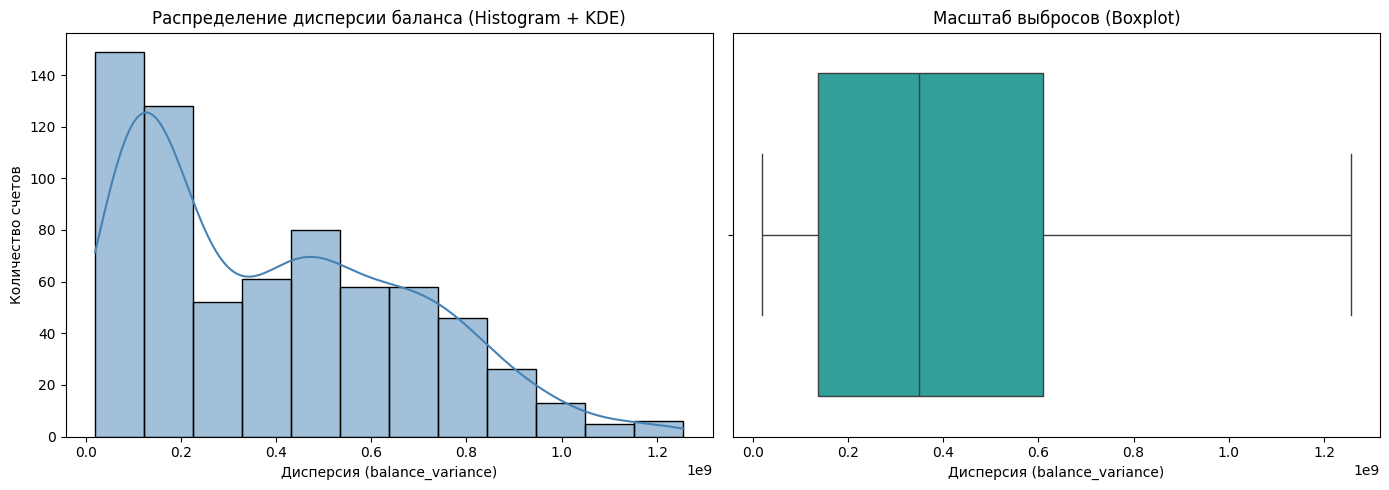

In [30]:
print(main_df['is_default'].value_counts(normalize=True, dropna=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=main_df, x='balance_variance', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение дисперсии баланса (Histogram + KDE)')
axes[0].set_xlabel('Дисперсия (balance_variance)')
axes[0].set_ylabel('Количество счетов')

sns.boxplot(data=main_df, x='balance_variance', ax=axes[1], color='lightseagreen')
axes[1].set_title('Масштаб выбросов (Boxplot)')
axes[1].set_xlabel('Дисперсия (balance_variance)')


plt.tight_layout()
plt.show()

Оценка дисбаланса целевой переменной (is_default):
Расчет частот показал, что выборка состоит примерно из 89% успешных кредитов (класс 0) и 11% дефолтов (класс 1), при этом пропущенные значения полностью отсутствуют.
Мы зафиксировали сильный дисбаланс классов, что является абсолютной нормой для кредитных портфелей. Это означает, что на этапе построения регрессии нам придется применять техники балансировки, иначе алгоритм пойдет по пути наименьшего сопротивления и начнет предсказывать всем клиентам успешный возврат долга.

Визуализация метрики финансовой стабильности показала следующую картину:

Гистограмма: Основная масса клиентов сгруппирована в левой части графика (низкая дисперсия, предсказуемое поведение).

Boxplot (ящик с усами): На графике видно, что у большинства клиентов остаток на счете ведет себя предсказуемо - центральная часть "ящика" плотно сбита и смещена влево. Однако небольшая группа заемщиков с огромными скачками в остатках вытягивает правый "ус" графика очень далеко вправо. При этом важно, что за пределами усов нет отдельно стоящих точек. Это значит, что даже самые сильные колебания баланса выглядят реалистично: в данных нет выбросов, которые нам пришлось бы вручную удалять перед проведением статистических тестов.

Уже визуально мы можем констатировать , что распределение остатка средств не является нормальным. Это дает математическое обоснование отказаться от классического t-теста Стьюдента и использовать непараметрический критерий Манна-Уитни для проверки первой гипотезы.

Проверка 1-ой гипотезы: Распределение дисперсии ежемесячного остатка на счете статистически значимо различается у надежных и проблемных заемщиков (медианный разброс баланса у клиентов в дефолте выше).

In [31]:
from scipy.stats import mannwhitneyu

# Сравниваем медианы в двух группах - успешных кредитов и дефолтов
print(main_df.groupby('is_default')['balance_variance'].median())

# Выделяем две выборки
variance_success = main_df[main_df['is_default'] == 0]['balance_variance'].dropna()
variance_default = main_df[main_df['is_default'] == 1]['balance_variance'].dropna()

stat, p_value = mannwhitneyu(variance_default, variance_success, alternative='two-sided')

print(f"Статистика U Манна-Уитни: {stat:.4f}")
print(f"P-value: {p_value:.4e}")

is_default
0    3.281889e+08
1    5.142383e+08
Name: balance_variance, dtype: float64
Статистика U Манна-Уитни: 28280.0000
P-value: 1.1805e-03


У надежных заемщиков (группа 0) типичный разброс баланса до момента выдачи кредита составляет около 328 миллионов. У клиентов в дефолте (группа 1) этот показатель достигает 514 миллионов. Мы видим глазами разницу более чем в полтора раза, которая подтверждает нашу бизнес-логику: счета дефолтников варьируются гораздо сильнее.

Поскольку P-value (около 0.001) уверенно меньше общепринятого жесткого порога значимости в 0.05 (5%), мы отвергаем нулевую гипотезу о равенстве групп. Статистический тест подтверждает, что признак balance_variance, даже будучи очищенным от утечки данных, обладает высокой разделяющей способностью и является надежным предиктором проблемного финансового поведения.


Проверка 2-ой гипотезы: Клиенты с высоким уровнем кредитной нагрузки (DTI > 0.3) уходят в дефолт значительно чаще.

In [32]:
dti_crosstab_pct = pd.crosstab(main_df['dti_category'], main_df['is_default'], normalize='index')
print("Доли дефолтов по группам нагрузки:")
print(dti_crosstab_pct)

Доли дефолтов по группам нагрузки:
is_default           0         1
dti_category                    
High Load     0.740741  0.259259
Normal Load   0.908486  0.091514


Визуальный анализ выявляет заметную разницу: доля дефолтов в сегменте нормальной долговой нагрузки составляет около 9%, тогда как в группе высокой нагрузки она достигает 26%. Однако эти пропорции требуют строгой статистической проверки, так как математические тесты опираются на абсолютный объем выборки. Для подтверждения того, что выявленная разница не является случайной флуктуацией, необходимо построить таблицу сопряженности в абсолютных значениях и применить критерий Хи-квадрат Пирсона.

In [33]:
from scipy.stats import chi2_contingency

contingency_absolute = pd.crosstab(main_df['dti_category'], main_df['is_default'])
print(contingency_absolute)
# Запускаем тест Хи-квадрат
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_absolute)

print(f"Статистика Хи-квадрат: {chi2_stat:.4f}")
print(f"P-value: {p_value:.4e}")

is_default      0   1
dti_category         
High Load      60  21
Normal Load   546  55
Статистика Хи-квадрат: 18.6255
P-value: 1.5908e-05


Поскольку полученное значение P-value многократно меньше общепринятого порога статистической значимости в 0.05 (5%), мы уверенно отвергаем нулевую гипотезу о независимости групп. Статистический тест Хи-квадрат подтверждает наличие сильной и статистически значимой связи между категориальным уровнем долговой нагрузки (DTI) и вероятностью наступления дефолта.Таким образом, разделение клиентов на сегменты по показателю DTI доказало свою состоятельность в качестве надежного фактора риска для построения модели. Однако нам стоит дополнительно удостовериться, что показатель значимо различается не только по искусственно заданному порогу, но и в своем исходном (непрерывном) виде у двух групп: надежных и проблемных заемщиков

In [34]:
dti_success = main_df[main_df['is_default'] == 0]['DTI'].dropna()
dti_default = main_df[main_df['is_default'] == 1]['DTI'].dropna()

stat, p_value = mannwhitneyu(dti_default, dti_success, alternative='two-sided')

print(f"Статистика U Манна-Уитни: {stat:.4f}")
print(f"P-value: {p_value:.4e}")

Статистика U Манна-Уитни: 30126.0000
P-value: 1.1667e-05


Результаты непараметрического теста Манна-Уитни показали наличие статистически значимых различий в распределении долговой нагрузки между надежными заемщиками и клиентами в дефолте (P-value приблизительно равен 1.17 * 10^-5, что строго меньше 0.05). Классическая гипотеза о прямом влиянии высокого DTI на дефолтность нашла строгое математическое подтверждение на данном кредитном портфеле. Разница в медианных значениях не является статистической случайностью.Признак DTI доказал свою высокую предиктивную силу и обязателен к включению в список предикторов. Его использование в логистической регрессии полностью математически обосновано и поможет алгоритму точнее калибровать уровень риска для заемщиков с высокой долговой нагрузкой.

3 этап. Машинное обучение (ML): Построение логистической регрессии для оценки индивидуальной вероятности дефолта новых клиентов на с использованием метрик, успешно прошедших статистическую проверку.

Прежде чем обучать саму модель, нам нужно собрать итоговый пул признаков и проверить их на мультиколлинеарность. Логистическая регрессия очень чувствительна к сильно скоррелированным (дублирующим друг друга) переменным - они ломают веса коэффициентов и делают модель неинтерпретируемой.


Возьмем все непрерывные фичи из нашей витрины (возраст, параметры кредита, транзакционные метрики и доказанную дисперсию баланса), за исключением отбракованного коэффициента DTI, и прогоним их через тепловую матрицу корреляций Спирмена (именно Спирмена, так как мы уже доказали, что распределение дисперсии у нас не является нормальным).

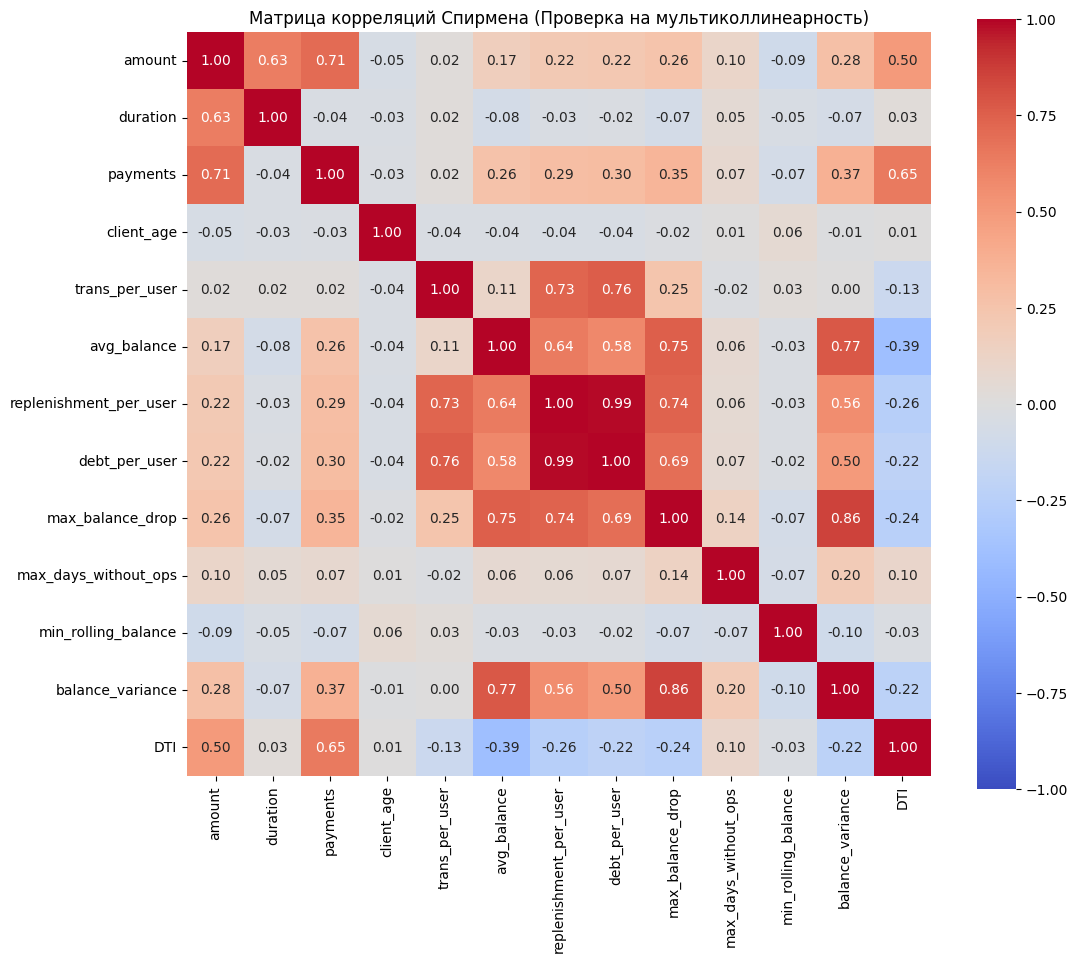

In [35]:
# Достаем только количество дней в виде числа
main_df['max_days_without_ops'] = main_df['max_days_without_ops'].astype(str).str.extract(r'(\d+)').astype(float)
# Формируем итоговый список потенциальных признаков для ML-модели
features_for_ml = [
    'amount', 'duration', 'payments', 'client_age', 
    'trans_per_user', 'avg_balance', 'replenishment_per_user', 
    'debt_per_user', 'max_balance_drop', 'max_days_without_ops', 
    'min_rolling_balance', 'balance_variance', 'DTI'
]

# Строим тепловую матрицу ранговых корреляций Спирмена
plt.figure(figsize=(12, 10))
corr_matrix = main_df[features_for_ml].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True)
plt.title('Матрица корреляций Спирмена (Проверка на мультиколлинеарность)')
plt.show()

Анализ матрицы ранговых корреляций Спирмена выявил две пары мультиколлинеарных признаков (коэффициент > 0.8):

1.Объем пополнений (replenishment_per_user) и объем списаний (debt_per_user) дублируют друг друга на 99%;
2.Максимальное падение баланса (max_balance_drop) на 86% коррелирует с общей дисперсией баланса (balance_variance).


Для обеспечения устойчивости логистической регрессии мы исключаем признаки replenishment_per_user и max_balance_drop из итогового набора предикторов. Теперь мы можем перейти к построению модели.

In [36]:
final_features = [
    'amount', 'duration', 'payments', 'client_age', 
    'trans_per_user', 'avg_balance', 'debt_per_user', 
    'max_days_without_ops', 'min_rolling_balance', 'balance_variance', 'DTI'
]

X = main_df[final_features].fillna(0)
y = main_df['is_default']

Чтобы оценка модели была объективной, алгоритм должен тестироваться на данных, которых он не видел при обучении. Отложим 25% нашей витрины в тестовую выборк - на ней мы проверим модель на качество.

Поскольку в данных присутствует сильный дисбаланс (всего 11% проблемных кредитов), резать датасет случайным образом опасно. Чтобы в тест случайно не попали только успешные или только дефолтные кейсы, мы используем параметр stratify=y. Он сработает как квотировщик и гарантирует, что историческая пропорция 89/11 строго сохранится в обеих частях.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.25, 
    random_state=42, 
    stratify=y
)

Логистическая регрессия крайне чувствительна к масштабу данных. Если возраст клиента измеряется десятками, а дисперсия баланса - сотнями миллионов, алгоритм может ошибочно счесть второй признак более значимым просто из-за количества нулей. Чтобы избежать этого математического искажения, мы приведем все переменные к единому масштабу с помощью StandardScaler. Важный нюанс: мы обучаем масштабировщик только на тренировочной выборке, чтобы алгоритм ничего не "подсмотрел" из тестовой.

In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Последний шаг перед обучением - решение проблемы сильного дисбаланса классов (11% дефолтов против 89% успешных возвратов). Если проигнорировать этот факт, модель просто научится отвечать «все вернут кредит» и получит формальную точность в 89%, оставаясь абсолютно бесполезной для бизнеса.

Вместо искусственного раздувания датасета (генерации синтетических данных), мы применим более элегантный метод встроенный параметр class_weight='balanced'. Он автоматически сместит веса внутри логистической регрессии, заставив алгоритм «штрафовать» себя за пропуск дефолтного клиента примерно сильнее, чем за ошибку на надежном заемщике.

In [39]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(class_weight='balanced', random_state=42)
log_reg.fit(X_train_scaled, y_train)

# (бинарные классы и вероятности от 0 до 1)
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

Проверим, как алгоритм справляется с новыми для него данными (на отложенной тестовой выборке). В кредитном скоринге мы не можем опираться на базовую метрику общей точности (Accuracy). Из-за сильного дисбаланса классов (дефолтов всего 11%) алгоритм мог бы предсказывать всем успешный возврат долга и формально быть правым в 89% случаев, но для бизнеса такая модель убыточна. В контексте нашей задачи положительным классом является именно наступление дефолта - то самое целевое событие, которое мы ищем. Поэтому мы оцениваем качество модели по метрикам для класса. Будем использовать профессиональные скоринговые метрики:

Recall показывает, какую долю от всех реальных дефолтников алгоритм смог обнаружить. В кредитовании эта метрика критически важна, так как опасно пропускать рисковые события: цена ошибки здесь - безвозвратная потеря выданного капитала.

Precision показывает, какая доля клиентов, названных моделью дефолтниками, действительно ими является. Эта метрика важна для контроля ложных срабатываний (False Positive). Если точность низкая, банк будет перестраховываться и массово отказывать надежным заемщикам, теряя лояльность аудитории и упуская процентную прибыль.

ROC-AUC Score оценивает глобальную разделяющую способность модели - насколько хорошо алгоритм в целом ранжирует заемщиков от самых надежных до самых рисковых.

In [40]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred))
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

              precision    recall  f1-score   support

           0       0.96      0.80      0.87       152
           1       0.31      0.74      0.44        19

    accuracy                           0.79       171
   macro avg       0.64      0.77      0.65       171
weighted avg       0.89      0.79      0.82       171

ROC-AUC Score: 0.8643


Обученная модель логистической регрессии продемонстрировала высокую предиктивную силу на отложенной тестовой выборке:

ROC-AUC (0.864): Отличная разделяющая способность. С вероятностью более 86% алгоритм оценит риск реального неплательщика выше, чем добросовестного заемщика. Это сильный показатель для банковского сектора, подтверждающий высокое качество собранных поведенческих предикторов.

Охват рисков (Recall = 74%): Алгоритм успешно выявляет почти 3 из 4 потенциальных должников. Внедрение такой модели позволит банку превентивно отказывать высокорискованным клиентам, радикально снижая прямые убытки от невозвращенных кредитов.

Точность отказов (Precision = 31%): Из всех клиентов, которым алгоритм рекомендует отказать, 31% действительно являются проблемными. В кредитном скоринге это математически обоснованный компромисс: благодаря параметру class_weight='balanced' модель настроена консервативно. Для бизнеса выгоднее перестраховаться и упустить процентную прибыль от части надежных заемщиков, чем потерять выданный капитал на пропущенном дефолте.

Общая точность (Accuracy = 79%): В 79% случаев итоговое решение алгоритма (одобрить или отказать) оказывается верным, что отражает оптимальный баланс между агрессивным выявлением рисков и сохранением качественной клиентской базы.

Итог проекта:

Поставленная бизнес-цель достигнута: проведен полный цикл исследования от агрегации сырых транзакционных данных с помощью SQL до статистической проверки гипотез и построения интерпретируемой ML-модели. Логистическая регрессия строго защищена от утечек данных, очищена от мультиколлинеарных признаков, адаптирована к дисбалансу классов и обладает высокой предсказательной силой (ROC-AUC = 0.864).

В реалиях финтеха разработанный алгоритм представляет собой надежный математический фундамент. Для полноценной интеграции в реальный бизнес-процесс модель потребует тестирование на свежем потоке заявок, настройки мониторинга смещения данных и обогащения профиля клиента внешними источниками (например, средней заработной платой в регионе его проживания, так как информация о регионе, в котором проживает заемщик, была в данных, но этим информация ограничивается). Тем не менее, проект убедительно доказывает ценность поведенческой аналитики и является полностью готовым ядром для внедрения скоринговой системы.